In [1]:
import xgboost, shap
print(xgboost.__version__, shap.__version__)

3.4.1 0.53.0


In [2]:
import pandas as pd
import numpy as np
import json
from pathlib import Path

BASE = Path(r"C:\Users\Administrator\credit-scoring-lc")
PROC = BASE / "data" / "processed"

train_d = pd.read_parquet(PROC / "train_features.parquet")
test_d  = pd.read_parquet(PROC / "test_features.parquet")

drop_cols = ["id", "issue_date", "issue_year", "split", "default_flag", "addr_state"]
feature_cols = [c for c in train_d.columns if c not in drop_cols]

X_train, y_train = train_d[feature_cols], train_d["default_flag"]
X_test,  y_test  = test_d[feature_cols],  test_d["default_flag"]

print(len(feature_cols), X_train.shape, X_test.shape)
print(round(y_train.mean(), 4), round(y_test.mean(), 4))
print("default_flag 混进特征了吗：", "default_flag" in feature_cols)

34 (262992, 34) (283026, 34)
0.1319 0.1489
default_flag 混进特征了吗： False


In [3]:
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score
from scipy.stats import ks_2samp

def ks_stat(y, p):
    y = np.asarray(y)
    return ks_2samp(p[y == 1], p[y == 0]).statistic

xgb = XGBClassifier(
    n_estimators=300, max_depth=4, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8, min_child_weight=50,
    eval_metric="auc", random_state=42, n_jobs=-1,
)
xgb.fit(X_train, y_train)

px_train = xgb.predict_proba(X_train)[:, 1]
px_test  = xgb.predict_proba(X_test)[:, 1]

print("AUC  train:", round(roc_auc_score(y_train, px_train), 4),
      " test:", round(roc_auc_score(y_test, px_test), 4))
print("KS   train:", round(ks_stat(y_train, px_train), 4),
      " test:", round(ks_stat(y_test, px_test), 4))

AUC  train: 0.6838  test: 0.6721
KS   train: 0.2657  test: 0.2495


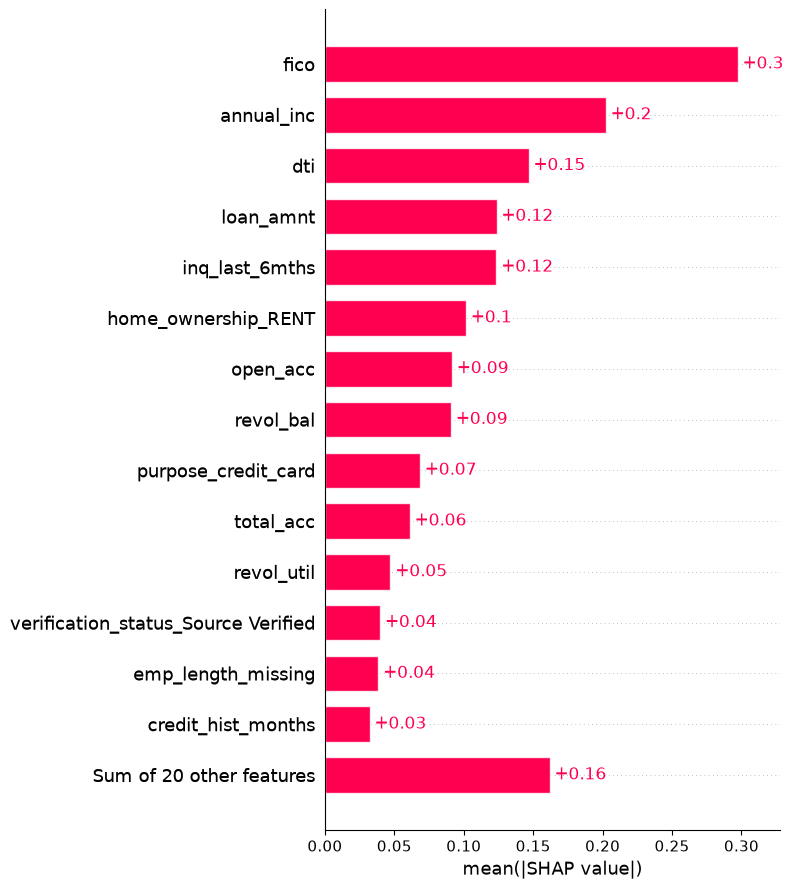

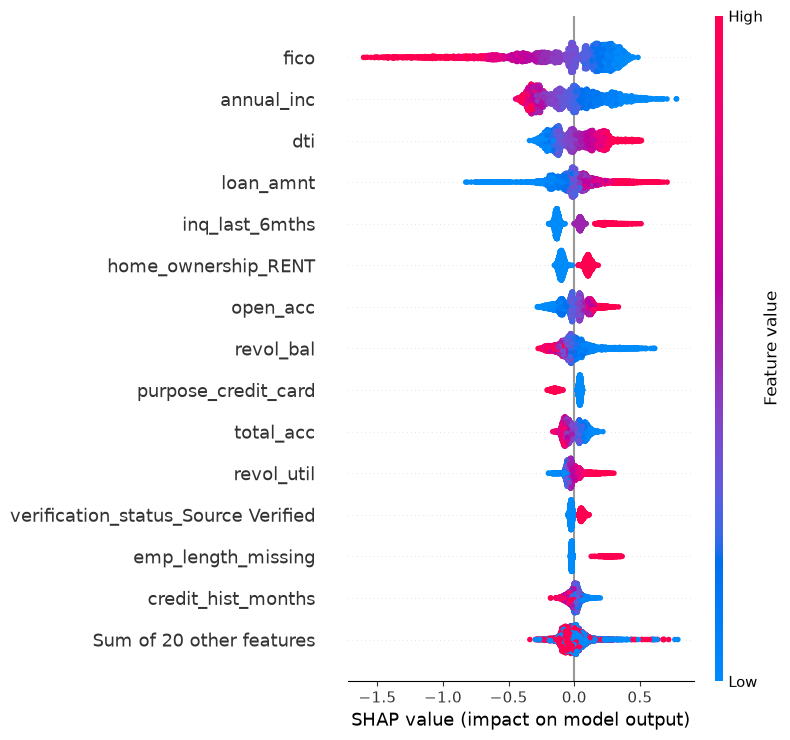

In [4]:
import shap
import matplotlib.pyplot as plt

X_sample = X_test.sample(5000, random_state=42)

explainer = shap.TreeExplainer(xgb)
sv = explainer(X_sample)

(BASE / "reports" / "figures").mkdir(parents=True, exist_ok=True)

plt.figure()
shap.plots.bar(sv, max_display=15, show=False)
plt.tight_layout()
plt.savefig(BASE / "reports" / "figures" / "shap_bar.png", dpi=150, bbox_inches="tight")
plt.show()

plt.figure()
shap.plots.beeswarm(sv, max_display=15, show=False)
plt.tight_layout()
plt.savefig(BASE / "reports" / "figures" / "shap_beeswarm.png", dpi=150, bbox_inches="tight")
plt.show()

复现检查 逻辑回归v2 test AUC: 0.6586  KS: 0.2296


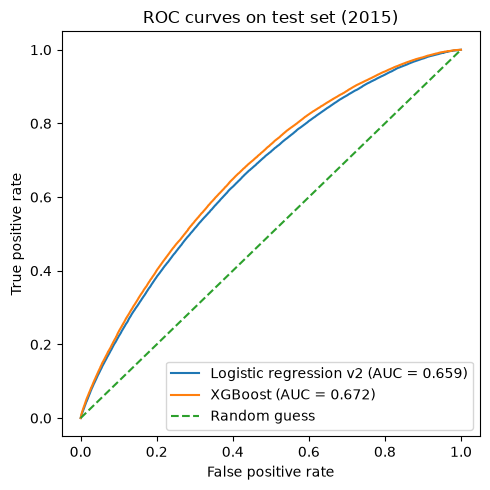

{'logistic_v2': {'auc_test': 0.6586, 'ks_test': 0.2296}, 'xgboost': {'auc_train': 0.6838, 'auc_test': 0.6721, 'ks_train': 0.2657, 'ks_test': 0.2495}}


In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_curve

rules = json.loads((BASE / "reports" / "preprocessing_rules.json").read_text(encoding="utf-8"))
cols_v2 = rules["logistic_v2_features"]

sc2 = StandardScaler().fit(train_d[cols_v2])
lr2 = LogisticRegression(max_iter=1000).fit(sc2.transform(train_d[cols_v2]), y_train)
p_lr = lr2.predict_proba(sc2.transform(test_d[cols_v2]))[:, 1]

print("复现检查 逻辑回归v2 test AUC:", round(roc_auc_score(y_test, p_lr), 4),
      " KS:", round(ks_stat(y_test, p_lr), 4))

fig, ax = plt.subplots(figsize=(5, 5))
for name, p in [("Logistic regression v2", p_lr), ("XGBoost", px_test)]:
    fpr, tpr, _ = roc_curve(y_test, p)
    ax.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, p):.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", label="Random guess")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("ROC curves on test set (2015)")
ax.legend(loc="lower right")
plt.tight_layout()
fig.savefig(BASE / "reports" / "figures" / "roc_comparison.png", dpi=150)
plt.show()

def f4(x):
    return round(float(x), 4)

metrics = {
    "logistic_v2": {"auc_test": f4(roc_auc_score(y_test, p_lr)),
                    "ks_test":  f4(ks_stat(y_test, p_lr))},
    "xgboost": {"auc_train": f4(roc_auc_score(y_train, px_train)),
                "auc_test":  f4(roc_auc_score(y_test, px_test)),
                "ks_train":  f4(ks_stat(y_train, px_train)),
                "ks_test":   f4(ks_stat(y_test, px_test))},
}
(BASE / "reports" / "metrics_comparison.json").write_text(
    json.dumps(metrics, indent=2), encoding="utf-8")
print(metrics)

In [6]:
print(type(ks_stat(y_test, px_test)))

<class 'numpy.float32'>


In [7]:
def f4(x):
    return round(float(x), 4)

metrics = {
    "logistic_v2": {"auc_test": f4(roc_auc_score(y_test, p_lr)),
                    "ks_test":  f4(ks_stat(y_test, p_lr))},
    "xgboost": {"auc_train": f4(roc_auc_score(y_train, px_train)),
                "auc_test":  f4(roc_auc_score(y_test, px_test)),
                "ks_train":  f4(ks_stat(y_train, px_train)),
                "ks_test":   f4(ks_stat(y_test, px_test))},
}
(BASE / "reports" / "metrics_comparison.json").write_text(
    json.dumps(metrics, indent=2), encoding="utf-8")
print(metrics)

{'logistic_v2': {'auc_test': 0.6586, 'ks_test': 0.2296}, 'xgboost': {'auc_train': 0.6838, 'auc_test': 0.6721, 'ks_train': 0.2657, 'ks_test': 0.2495}}
